In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path

# --- Project root (robust to folder moves) ---
# Default to the known location; fall back to the current working directory
# if the project has been moved again (launch JupyterLab from the project folder).
PROJECT_ROOT = Path.home() / "Claude" / "Projects" / "Directed Study" / "Ransomware"
if not (PROJECT_ROOT / "features").exists():
    PROJECT_ROOT = Path.cwd()
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.manifold import TSNE
import umap
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sentence_transformers import SentenceTransformer

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Paths
DATA_ROOT    = PROJECT_ROOT / "dataset"
FEATURES_DIR = PROJECT_ROOT / "features"

# Class definitions
RANSOMWARE_CLASSES    = ["WannaCry", "Ryuk", "REvil", "LockBit", "Darkside", "Conti"]
LEGIT_ENC_CLASSES     = ["AESCrypt", "SDelete", "Zip"]
BENIGN_CLASSES        = ["Firefox", "Office", "Idle"]
ALL_ORIGINAL_CLASSES  = RANSOMWARE_CLASSES + LEGIT_ENC_CLASSES + BENIGN_CLASSES
VARIANT_CLASSES       = [f"Conti_{i:02d}" for i in range(1, 8)]

# 3-way label mapping
def get_3way_label(class_name):
    if class_name in RANSOMWARE_CLASSES: return "ransomware"
    if class_name in LEGIT_ENC_CLASSES:  return "legit_encryption"
    if class_name in BENIGN_CLASSES:     return "benign"
    return "unknown"

# Colors
CLASS_COLORS = {
    "ransomware":       "#e6194b",
    "legit_encryption": "#f58231",
    "benign":           "#4363d8",
    "variant":          "#3cb44b",
}

# T_window parameters
T_WINDOW    = 0.1
T_D         = 30.0
T_WINDOW_NS = int(T_WINDOW * 1_000_000_000)
T_D_NS      = int(T_D      * 1_000_000_000)

print("Config loaded.")
print(f"3-way classes:")
print(f"  Ransomware:        {RANSOMWARE_CLASSES}")
print(f"  Legit Encryption:  {LEGIT_ENC_CLASSES}")
print(f"  Benign:            {BENIGN_CLASSES}")
print(f"  Zero-day proxies:  {VARIANT_CLASSES}")

/home/arshad/Claude/Projects/Directed Study/Ransomware/ransmap_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cpu
Config loaded.
3-way classes:
  Ransomware:        ['WannaCry', 'Ryuk', 'REvil', 'LockBit', 'Darkside', 'Conti']
  Legit Encryption:  ['AESCrypt', 'SDelete', 'Zip']
  Benign:            ['Firefox', 'Office', 'Idle']
  Zero-day proxies:  ['Conti_01', 'Conti_02', 'Conti_03', 'Conti_04', 'Conti_05', 'Conti_06', 'Conti_07']


In [2]:
def log_lines_to_text(ata_write_lines, mem_write_lines):
    """
    Convert raw log lines from a 0.1s window into a natural language
    paragraph describing the behavioral pattern.

    Preserves individual access events — not statistics.
    Each line becomes a token describing one actual hardware event.
    Empty windows get a meaningful null description.
    """
    tokens = []

    # Storage write events
    if ata_write_lines.empty:
        tokens.append("no storage write activity")
    else:
        for _, row in ata_write_lines.iterrows():
            size    = int(row.iloc[3]) if not pd.isna(row.iloc[3]) else 0
            entropy = float(row.iloc[4]) if not pd.isna(row.iloc[4]) else -1.0

            if entropy < 0:
                ent_label = "unknown"
            elif entropy > 0.9:
                ent_label = "very-high-entropy"
            elif entropy > 0.7:
                ent_label = "high-entropy"
            elif entropy > 0.4:
                ent_label = "moderate-entropy"
            elif entropy > 0.1:
                ent_label = "low-entropy"
            else:
                ent_label = "near-zero-entropy"

            size_label = "large-write" if size > 65536 else \
                         "medium-write" if size > 4096 else "small-write"

            tokens.append(f"storage-write {size_label} {ent_label}")

    # Memory write events
    if mem_write_lines.empty:
        tokens.append("no memory write activity")
    else:
        for _, row in mem_write_lines.iterrows():
            entropy  = float(row.iloc[4]) if not pd.isna(row.iloc[4]) else 0.0
            mem_type = int(row.iloc[5])   if not pd.isna(row.iloc[5]) else 1

            type_label = {1: "4kb-page", 2: "2mb-page", 4: "mmio"}.get(mem_type, "unknown-page")

            if entropy > 0.9:   ent_label = "very-high-entropy"
            elif entropy > 0.7: ent_label = "high-entropy"
            elif entropy > 0.4: ent_label = "moderate-entropy"
            elif entropy > 0.1: ent_label = "low-entropy"
            else:               ent_label = "near-zero-entropy"

            tokens.append(f"memory-write {type_label} {ent_label}")

    # Truncate to fit within 512 token budget (73 events max)
    tokens = tokens[:73]
    return " . ".join(tokens)


# Test on a real execution
test_dir = DATA_ROOT / "ddr4-2133-16g" / "WannaCry"
test_exec = sorted([d for d in test_dir.iterdir() if d.is_dir()])[0]

ata_w = pd.read_csv(test_exec / "ata_write.csv", header=None)
mem_w = pd.read_csv(test_exec / "mem_write.csv", header=None)

# Get first window
ref_ns = min(
    int(ata_w.iloc[0, 0]) * 1_000_000_000 + int(ata_w.iloc[0, 1]),
    int(mem_w.iloc[0, 0]) * 1_000_000_000 + int(mem_w.iloc[0, 1])
)

ata_rel = (ata_w.iloc[:, 0].astype(np.int64) * 1_000_000_000 +
           ata_w.iloc[:, 1].astype(np.int64)) - ref_ns
mem_rel = (mem_w.iloc[:, 0].astype(np.int64) * 1_000_000_000 +
           mem_w.iloc[:, 1].astype(np.int64)) - ref_ns

w_ata = ata_w[(ata_rel >= 0) & (ata_rel < T_WINDOW_NS)]
w_mem = mem_w[(mem_rel >= 0) & (mem_rel < T_WINDOW_NS)]

text = log_lines_to_text(w_ata, w_mem)
print(f"Example window text (WannaCry, window 0):")
print(f"  Lines: {len(w_ata)} ATA write + {len(w_mem)} mem write")
print(f"  Text:  {text[:300]}...")

Example window text (WannaCry, window 0):
  Lines: 0 ATA write + 21 mem write
  Text:  no storage write activity . memory-write 2mb-page high-entropy . memory-write 2mb-page moderate-entropy . memory-write 2mb-page high-entropy . memory-write 2mb-page high-entropy . memory-write 2mb-page high-entropy . memory-write 2mb-page high-entropy . memory-write 2mb-page low-entropy . memory-wri...


In [3]:
def extract_text_windows(exec_dir):
    """
    Extract text descriptions for all 0.1s windows across T_d = 30s.
    Returns list of 300 text strings — one per window.
    """
    ata_w_path = exec_dir / "ata_write.csv"
    mem_w_path = exec_dir / "mem_write.csv"

    ata_w = pd.DataFrame()
    mem_w = pd.DataFrame()

    if ata_w_path.exists() and ata_w_path.stat().st_size > 0:
        try:
            ata_w = pd.read_csv(ata_w_path, header=None)
        except:
            pass

    if mem_w_path.exists() and mem_w_path.stat().st_size > 0:
        try:
            mem_w = pd.read_csv(mem_w_path, header=None)
        except:
            pass

    # Compute reference timestamp
    ref_ns = None
    if not ata_w.empty:
        t = int(ata_w.iloc[0, 0]) * 1_000_000_000 + int(ata_w.iloc[0, 1])
        ref_ns = t
    if not mem_w.empty:
        t = int(mem_w.iloc[0, 0]) * 1_000_000_000 + int(mem_w.iloc[0, 1])
        ref_ns = t if ref_ns is None else min(ref_ns, t)

    if ref_ns is None:
        return ["no activity"] * 300

    # Add relative timestamps
    if not ata_w.empty:
        ata_rel = (ata_w.iloc[:, 0].astype(np.int64) * 1_000_000_000 +
                   ata_w.iloc[:, 1].astype(np.int64)) - ref_ns
        ata_w = ata_w.copy()
        ata_w["rel_ns"] = ata_rel

    if not mem_w.empty:
        mem_rel = (mem_w.iloc[:, 0].astype(np.int64) * 1_000_000_000 +
                   mem_w.iloc[:, 1].astype(np.int64)) - ref_ns
        mem_w = mem_w.copy()
        mem_w["rel_ns"] = mem_rel

    windows = []
    t = 0
    while t <= T_D_NS - T_WINDOW_NS:
        t_end = t + T_WINDOW_NS

        w_ata = pd.DataFrame()
        w_mem = pd.DataFrame()

        if not ata_w.empty:
            mask = (ata_w["rel_ns"] >= t) & (ata_w["rel_ns"] < t_end)
            w_ata = ata_w[mask]
        if not mem_w.empty:
            mask = (mem_w["rel_ns"] >= t) & (mem_w["rel_ns"] < t_end)
            w_mem = mem_w[mask]

        windows.append(log_lines_to_text(w_ata, w_mem))
        t += T_WINDOW_NS

    return windows


# Quick test
windows = extract_text_windows(test_exec)
print(f"Windows extracted: {len(windows)}")
print(f"\nWindow 0 (early):  {windows[0][:150]}")
print(f"\nWindow 50 (mid):   {windows[50][:150]}")
print(f"\nWindow 150 (late): {windows[150][:150]}")

Windows extracted: 300

Window 0 (early):  no storage write activity . memory-write 2mb-page high-entropy . memory-write 2mb-page moderate-entropy . memory-write 2mb-page high-entropy . memory-

Window 50 (mid):   storage-write small-write low-entropy . memory-write 2mb-page high-entropy . memory-write mmio near-zero-entropy . memory-write mmio near-zero-entropy

Window 150 (late): storage-write small-write moderate-entropy . storage-write small-write moderate-entropy . storage-write small-write moderate-entropy . storage-write s


In [4]:
# This cell processes all execution directories
# and produces text windows for the sentence transformer

meta_df = pd.read_csv(FEATURES_DIR / "metadata.csv")

all_windows  = []   # list of lists — each inner list is 300 window texts
all_labels   = []   # class name per execution
all_3way     = []   # 3-way label per execution
all_groups   = []   # original / variant

print(f"Processing {len(meta_df)} execution directories...")
print("This may take a few minutes.\n")

for i, row in meta_df.iterrows():
    exec_dir   = Path(row["exec_dir"])
    label      = row["label"]
    group      = row["group"]
    label_3way = get_3way_label(label) if group == "original" else "variant"

    windows = extract_text_windows(exec_dir)

    all_windows.append(windows)
    all_labels.append(label)
    all_3way.append(label_3way)
    all_groups.append(group)

    if (i + 1) % 20 == 0:
        print(f"  Processed {i+1}/{len(meta_df)}")

all_labels = np.array(all_labels)
all_3way   = np.array(all_3way)
all_groups = np.array(all_groups)

print(f"\nDone.")
print(f"Total executions:  {len(all_windows)}")
print(f"Windows per exec:  {len(all_windows[0])}")
print(f"\n3-way label distribution:")
for label in np.unique(all_3way):
    print(f"  {label:<20}: {(all_3way == label).sum()}")

Processing 190 execution directories...
This may take a few minutes.

  Processed 20/190
  Processed 40/190
  Processed 60/190
  Processed 80/190
  Processed 100/190
  Processed 120/190
  Processed 140/190
  Processed 160/190
  Processed 180/190

Done.
Total executions:  190
Windows per exec:  300

3-way label distribution:
  benign              : 30
  legit_encryption    : 30
  ransomware          : 60
  variant             : 70


In [5]:
# Flatten all windows into one list for batch embedding
# Then reshape back to (n_executions, 300, 384)

print("Loading sentence transformer...")
st_model = SentenceTransformer("all-MiniLM-L6-v2")
emb_dim  = st_model.get_sentence_embedding_dimension()
print(f"Embedding dimension: {emb_dim}")

# Flatten
flat_windows = [w for exec_windows in all_windows for w in exec_windows]
print(f"\nTotal windows to embed: {len(flat_windows)}")
print("Embedding... (this will take several minutes)")

flat_embeddings = st_model.encode(
    flat_windows,
    batch_size=256,
    show_progress_bar=True,
    convert_to_numpy=True
)

print(f"\nFlat embeddings shape: {flat_embeddings.shape}")

# Reshape to (n_executions, 300, 384)
n_exec    = len(all_windows)
n_windows = len(all_windows[0])
text_seqs  = flat_embeddings.reshape(n_exec, n_windows, emb_dim)

print(f"Reshaped: {text_seqs.shape}  (executions, windows, embedding_dim)")

# Save to disk — this takes time to compute, don't redo it
np.save(FEATURES_DIR / "text_sequences.npy", text_seqs)
np.save(FEATURES_DIR / "text_labels.npy",    all_labels)
np.save(FEATURES_DIR / "text_3way.npy",      all_3way)
np.save(FEATURES_DIR / "text_groups.npy",    all_groups)
print("Saved to disk.")

Loading sentence transformer...


Loading weights: 100%|██████████████████████| 103/103 [00:00<00:00, 4442.20it/s]
/tmp/ipykernel_30671/1733396111.py:6: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  emb_dim  = st_model.get_sentence_embedding_dimension()


Embedding dimension: 384

Total windows to embed: 57000
Embedding... (this will take several minutes)


Batches: 100%|████████████████████████████████| 223/223 [16:15<00:00,  4.37s/it]



Flat embeddings shape: (57000, 384)
Reshaped: (190, 300, 384)  (executions, windows, embedding_dim)
Saved to disk.


/home/arshad/Claude/Projects/Directed Study/Ransomware/ransmap_env/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


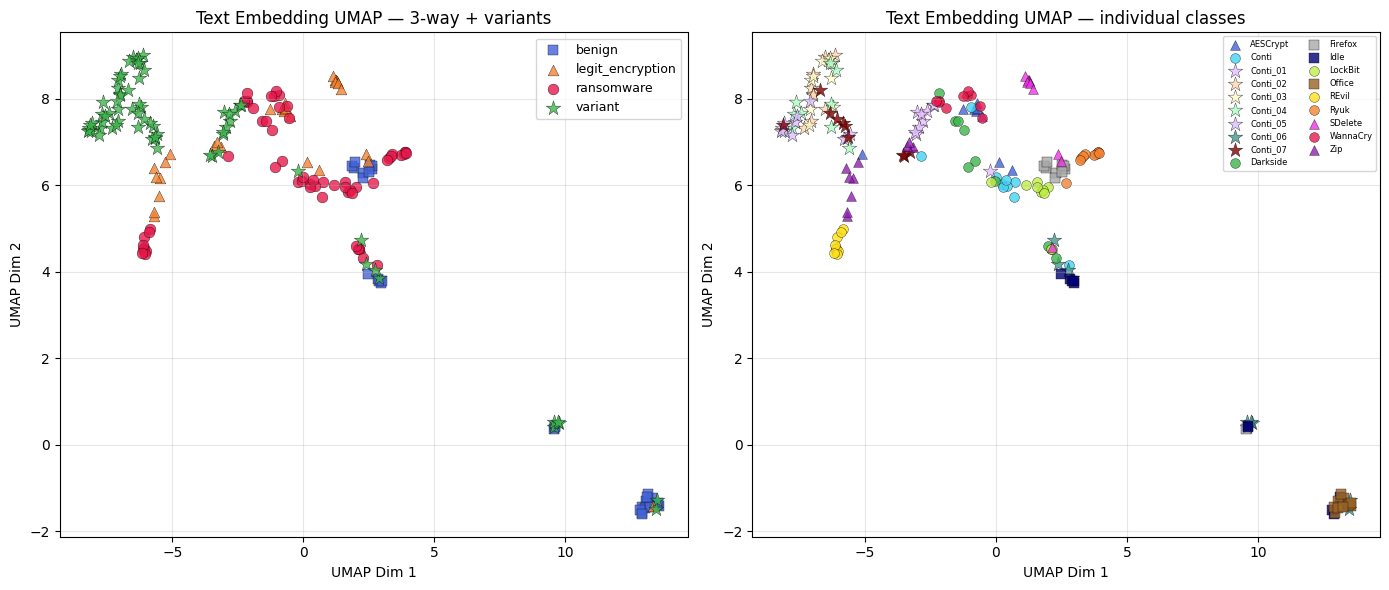

In [8]:
# Mean pool across 300 windows → (n_exec, 384)
# Then UMAP to 2D to check if 3-way structure is visible

text_mean = text_seqs.mean(axis=1)  # (190, 384)

reducer = umap.UMAP(n_components=2, n_neighbors=15,
                    min_dist=0.1, metric="cosine", random_state=42)
text_2d = reducer.fit_transform(text_mean)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left — 3-way + variant
ax = axes[0]
color_map = {
    "ransomware":       "#e6194b",
    "legit_encryption": "#f58231",
    "benign":           "#4363d8",
    "variant":          "#3cb44b",
}
marker_map = {
    "ransomware": "o", "legit_encryption": "^",
    "benign": "s",     "variant": "*",
}
for grp in np.unique(all_3way):
    mask   = all_3way == grp
    color  = color_map[grp]
    marker = marker_map[grp]
    size   = 120 if marker == "*" else 60
    ax.scatter(text_2d[mask, 0], text_2d[mask, 1],
               c=color, marker=marker, s=size,
               alpha=0.8, edgecolors="k", linewidths=0.3,
               label=grp)
ax.set_title("Text Embedding UMAP — 3-way + variants")
ax.legend(fontsize=9)
ax.set_xlabel("UMAP Dim 1")
ax.set_ylabel("UMAP Dim 2")
ax.grid(True, alpha=0.3)

# Right — individual classes
ax = axes[1]
ind_colors = {
    "WannaCry": "#e6194b", "Ryuk": "#f58231",   "REvil": "#ffe119",
    "LockBit":  "#bfef45", "Darkside": "#3cb44b","Conti": "#42d4f4",
    "AESCrypt": "#4363d8", "Zip": "#911eb4",     "SDelete": "#f032e6",
    "Firefox":  "#a9a9a9", "Office": "#9a6324",  "Idle": "#000075",
    "Conti_01": "#e6beff", "Conti_02": "#ffd8b1","Conti_03": "#fffac8",
    "Conti_04": "#aaffc3", "Conti_05": "#dcbeff","Conti_06": "#469990",
    "Conti_07": "#800000",
}
ind_markers = {}
for c in RANSOMWARE_CLASSES:  ind_markers[c] = "o"
for c in LEGIT_ENC_CLASSES:   ind_markers[c] = "^"
for c in BENIGN_CLASSES:      ind_markers[c] = "s"
for c in VARIANT_CLASSES:     ind_markers[c] = "*"

for label in np.unique(all_labels):
    mask   = all_labels == label
    color  = ind_colors.get(label, "#333333")
    marker = ind_markers.get(label, "o")
    size   = 120 if marker == "*" else 50
    ax.scatter(text_2d[mask, 0], text_2d[mask, 1],
               c=color, marker=marker, s=size,
               alpha=0.8, edgecolors="k", linewidths=0.3,
               label=label)
ax.set_title("Text Embedding UMAP — individual classes")
ax.legend(fontsize=6, ncol=2)
ax.set_xlabel("UMAP Dim 1")
ax.set_ylabel("UMAP Dim 2")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FEATURES_DIR / "text_embedding_3way_umap.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
# For the 3-way classification problem we use the full
# (300, 384) sequence per execution — not mean pooled.
# The classifier sees the temporal evolution of embeddings.

class SlidingWindowDataset(Dataset):
    """
    Each sample is one execution: shape (300, 384)
    Label is 3-way: ransomware / legit_encryption / benign
    Variants are excluded from training.
    """
    def __init__(self, sequences, labels_3way, mask=None):
        if mask is not None:
            sequences   = sequences[mask]
            labels_3way = labels_3way[mask]
        self.X = torch.tensor(sequences, dtype=torch.float32)
        self.y = labels_3way

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# Encode labels
le = LabelEncoder()
train_mask = all_groups == "original"

y_encoded_all = np.zeros(len(all_3way), dtype=np.int64)
y_encoded_all[train_mask] = le.fit_transform(all_3way[train_mask])

print(f"Label encoding: {dict(zip(le.classes_, le.transform(le.classes_)))}")
print(f"Training samples: {train_mask.sum()}")
print(f"Variant samples (held out): {(~train_mask).sum()}")

# Train/val split — 80/20 within original classes
from sklearn.model_selection import train_test_split

orig_indices = np.where(train_mask)[0]
train_idx, val_idx = train_test_split(
    orig_indices, test_size=0.2, random_state=42,
    stratify=all_3way[train_mask]
)

train_mask_split = np.zeros(len(all_3way), dtype=bool)
val_mask_split   = np.zeros(len(all_3way), dtype=bool)
train_mask_split[train_idx] = True
val_mask_split[val_idx]     = True

train_dataset = SlidingWindowDataset(text_seqs, y_encoded_all, train_mask_split)
val_dataset   = SlidingWindowDataset(text_seqs, y_encoded_all, val_mask_split)

train_loader  = DataLoader(train_dataset, batch_size=8, shuffle=True)
val_loader    = DataLoader(val_dataset,   batch_size=8, shuffle=False)

print(f"\nTrain: {len(train_dataset)}  Val: {len(val_dataset)}")

Label encoding: {np.str_('benign'): np.int64(0), np.str_('legit_encryption'): np.int64(1), np.str_('ransomware'): np.int64(2)}
Training samples: 120
Variant samples (held out): 70

Train: 96  Val: 24


In [11]:
class TextEmbeddingClassifier(nn.Module):
    """
    Takes a (300, 384) sequence of text embeddings — one per 0.1s window.
    Uses a 1D-CNN to extract local temporal patterns,
    followed by mean pooling and a classification head.

    Three output classes:
        0 = benign
        1 = legit_encryption
        2 = ransomware
    """
    def __init__(self, seq_len=300, emb_dim=384, n_classes=3):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv1d(emb_dim, 128, kernel_size=5, padding=2),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Conv1d(128, 64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(),
        )

        self.classifier = nn.Sequential(
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(32, n_classes),
        )

        # Reconstruction head for zero-day anomaly detection
        self.reconstructor = nn.Sequential(
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, emb_dim),
        )

    def forward(self, x):
        # x: (batch, 300, 384)
        x_t  = x.permute(0, 2, 1)       # (batch, 384, 300)
        feat = self.conv(x_t)            # (batch, 64, 300)
        pooled = feat.mean(dim=2)        # (batch, 64)
        logits = self.classifier(pooled) # (batch, 3)
        recon  = self.reconstructor(pooled)  # (batch, 384) — for anomaly score
        return logits, recon, pooled

clf_model = TextEmbeddingClassifier().to(device)
total_params = sum(p.numel() for p in clf_model.parameters())
print(f"Classifier parameters: {total_params:,}")
print(clf_model)

Classifier parameters: 347,331
TextEmbeddingClassifier(
  (conv): Sequential(
    (0): Conv1d(384, 128, kernel_size=(5,), stride=(1,), padding=(2,))
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv1d(128, 64, kernel_size=(5,), stride=(1,), padding=(2,))
    (4): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
  )
  (classifier): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=32, out_features=3, bias=True)
  )
  (reconstructor): Sequential(
    (0): Linear(in_features=64, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=384, bias=True)
  )
)


In [12]:
EPOCHS    = 80
LR        = 1e-3
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(clf_model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=25, gamma=0.5)

train_losses, val_losses, val_accs = [], [], []

print(f"{'Epoch':>6}  {'Train Loss':>11}  {'Val Loss':>10}  {'Val Acc':>9}")
print("-" * 45)

for epoch in range(1, EPOCHS + 1):
    # Train
    clf_model.train()
    epoch_loss = 0.0
    for batch_x, batch_y in train_loader:
        batch_x = batch_x.to(device)
        batch_y = torch.tensor(batch_y, dtype=torch.long).to(device)
        optimizer.zero_grad()
        logits, _, _ = clf_model(batch_x)
        loss = criterion(logits, batch_y)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    # Validate
    clf_model.eval()
    val_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for batch_x, batch_y in val_loader:
            batch_x = batch_x.to(device)
            batch_y = torch.tensor(batch_y, dtype=torch.long).to(device)
            logits, _, _ = clf_model(batch_x)
            val_loss += criterion(logits, batch_y).item()
            preds    = logits.argmax(dim=1)
            correct  += (preds == batch_y).sum().item()
            total    += len(batch_y)

    avg_train = epoch_loss / len(train_loader)
    avg_val   = val_loss   / len(val_loader)
    acc       = correct / total

    train_losses.append(avg_train)
    val_losses.append(avg_val)
    val_accs.append(acc)
    scheduler.step()

    if epoch % 10 == 0 or epoch == 1:
        print(f"{epoch:>6}  {avg_train:>11.4f}  {avg_val:>10.4f}  {acc:>8.2%}")

print("\nTraining complete.")

 Epoch   Train Loss    Val Loss    Val Acc
---------------------------------------------


/tmp/ipykernel_30671/3429719367.py:18: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  batch_y = torch.tensor(batch_y, dtype=torch.long).to(device)
/tmp/ipykernel_30671/3429719367.py:32: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  batch_y = torch.tensor(batch_y, dtype=torch.long).to(device)


     1       1.0013      1.0503    50.00%
    10       0.5373      0.8628    70.83%
    20       0.2868      0.4347    91.67%
    30       0.1876      0.2066    95.83%
    40       0.1147      0.2327    95.83%
    50       0.0874      0.2111    95.83%
    60       0.0547      0.1283    95.83%
    70       0.0714      0.1355    95.83%
    80       0.0704      0.1362    95.83%

Training complete.


Classification Report — Original Classes (3-way)
                  precision    recall  f1-score   support

          benign       0.97      1.00      0.98        30
legit_encryption       1.00      0.97      0.98        30
      ransomware       1.00      1.00      1.00        60

        accuracy                           0.99       120
       macro avg       0.99      0.99      0.99       120
    weighted avg       0.99      0.99      0.99       120



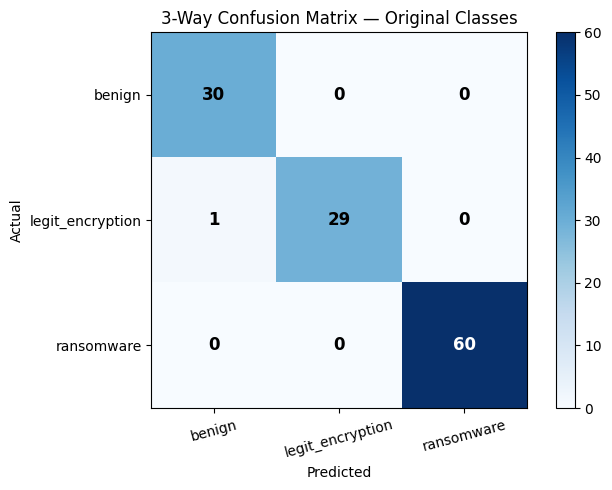

In [13]:
clf_model.eval()

all_preds, all_true, all_scores = [], [], []

full_orig_dataset = SlidingWindowDataset(text_seqs, y_encoded_all, train_mask)
full_orig_loader  = DataLoader(full_orig_dataset, batch_size=8, shuffle=False)

with torch.no_grad():
    for batch_x, batch_y in full_orig_loader:
        batch_x = batch_x.to(device)
        logits, _, _ = clf_model(batch_x)
        probs  = torch.softmax(logits, dim=1)
        preds  = logits.argmax(dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_true.extend(batch_y.numpy())
        all_scores.extend(probs.cpu().numpy())

all_preds  = np.array(all_preds)
all_true   = np.array(all_true)
all_scores = np.array(all_scores)

print("Classification Report — Original Classes (3-way)")
print("=" * 55)
print(classification_report(all_true, all_preds,
                             target_names=le.classes_))

# Confusion matrix
cm = confusion_matrix(all_true, all_preds)
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(3))
ax.set_yticks(range(3))
ax.set_xticklabels(le.classes_, rotation=15)
ax.set_yticklabels(le.classes_)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("3-Way Confusion Matrix — Original Classes")
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i,j], ha="center", va="center",
                color="white" if cm[i,j] > cm.max()/2 else "black",
                fontsize=12, fontweight="bold")
plt.colorbar(im)
plt.tight_layout()
plt.savefig(FEATURES_DIR / "text_3way_confusion.png", dpi=150)
plt.show()

In [14]:
# Variants were never seen during training
# Two signals tested:
#   1. Reconstruction error — high = anomalous = zero-day
#   2. Classification confidence — low max probability = uncertain = zero-day

variant_mask    = all_groups == "variant"
variant_dataset = SlidingWindowDataset(text_seqs, y_encoded_all, variant_mask)
variant_loader  = DataLoader(variant_dataset, batch_size=8, shuffle=False)

var_recon_errors = []
var_max_probs    = []
var_preds        = []

clf_model.eval()
with torch.no_grad():
    for batch_x, batch_y in variant_loader:
        batch_x = batch_x.to(device)
        logits, recon, pooled = clf_model(batch_x)

        # Mean text embedding of input for reconstruction comparison
        mean_input = batch_x.mean(dim=1)  # (batch, 384)
        recon_err  = ((recon - mean_input) ** 2).mean(dim=1)

        probs     = torch.softmax(logits, dim=1)
        max_prob  = probs.max(dim=1).values
        pred      = logits.argmax(dim=1)

        var_recon_errors.extend(recon_err.cpu().numpy())
        var_max_probs.extend(max_prob.cpu().numpy())
        var_preds.extend(pred.cpu().numpy())

var_recon_errors = np.array(var_recon_errors)
var_max_probs    = np.array(var_max_probs)
var_preds        = np.array(var_preds)
var_labels       = all_labels[variant_mask]

print("Zero-Day Detection — Conti Variants")
print("=" * 65)
print(f"{'Variant':<12}  {'Pred Class':<18}  {'Max Prob':>9}  {'Recon Err':>10}")
print("-" * 55)

for i, variant in enumerate(VARIANT_CLASSES):
    mask  = var_labels == variant
    if mask.sum() == 0:
        continue
    pred_class = le.classes_[int(np.round(var_preds[mask].mean()))]
    avg_prob   = var_max_probs[mask].mean()
    avg_recon  = var_recon_errors[mask].mean()
    print(f"{variant:<12}  {pred_class:<18}  {avg_prob:>9.4f}  {avg_recon:>10.4f}")

# Compare recon error: known ransomware vs variants
known_ransomware_dataset = SlidingWindowDataset(
    text_seqs, y_encoded_all,
    (all_groups == "original") & np.isin(all_labels, RANSOMWARE_CLASSES)
)
known_loader = DataLoader(known_ransomware_dataset, batch_size=8, shuffle=False)

known_recon = []
with torch.no_grad():
    for batch_x, batch_y in known_loader:
        batch_x   = batch_x.to(device)
        _, recon, _ = clf_model(batch_x)
        mean_input  = batch_x.mean(dim=1)
        recon_err   = ((recon - mean_input) ** 2).mean(dim=1)
        known_recon.extend(recon_err.cpu().numpy())

print(f"\nReconstruction error comparison:")
print(f"  Known ransomware mean: {np.mean(known_recon):.4f}")
print(f"  Variant mean:          {var_recon_errors.mean():.4f}")
print(f"  Ratio:                 {var_recon_errors.mean() / np.mean(known_recon):.2f}x")

Zero-Day Detection — Conti Variants
Variant       Pred Class           Max Prob   Recon Err
-------------------------------------------------------
Conti_01      ransomware             0.9993      0.0298
Conti_02      ransomware             0.9804      0.0260
Conti_03      ransomware             0.9414      0.0235
Conti_04      ransomware             0.9977      0.0287
Conti_05      ransomware             0.9979      0.0314
Conti_06      legit_encryption       0.8913      0.0157
Conti_07      ransomware             0.9824      0.0191

Reconstruction error comparison:
  Known ransomware mean: 0.0214
  Variant mean:          0.0249
  Ratio:                 1.16x


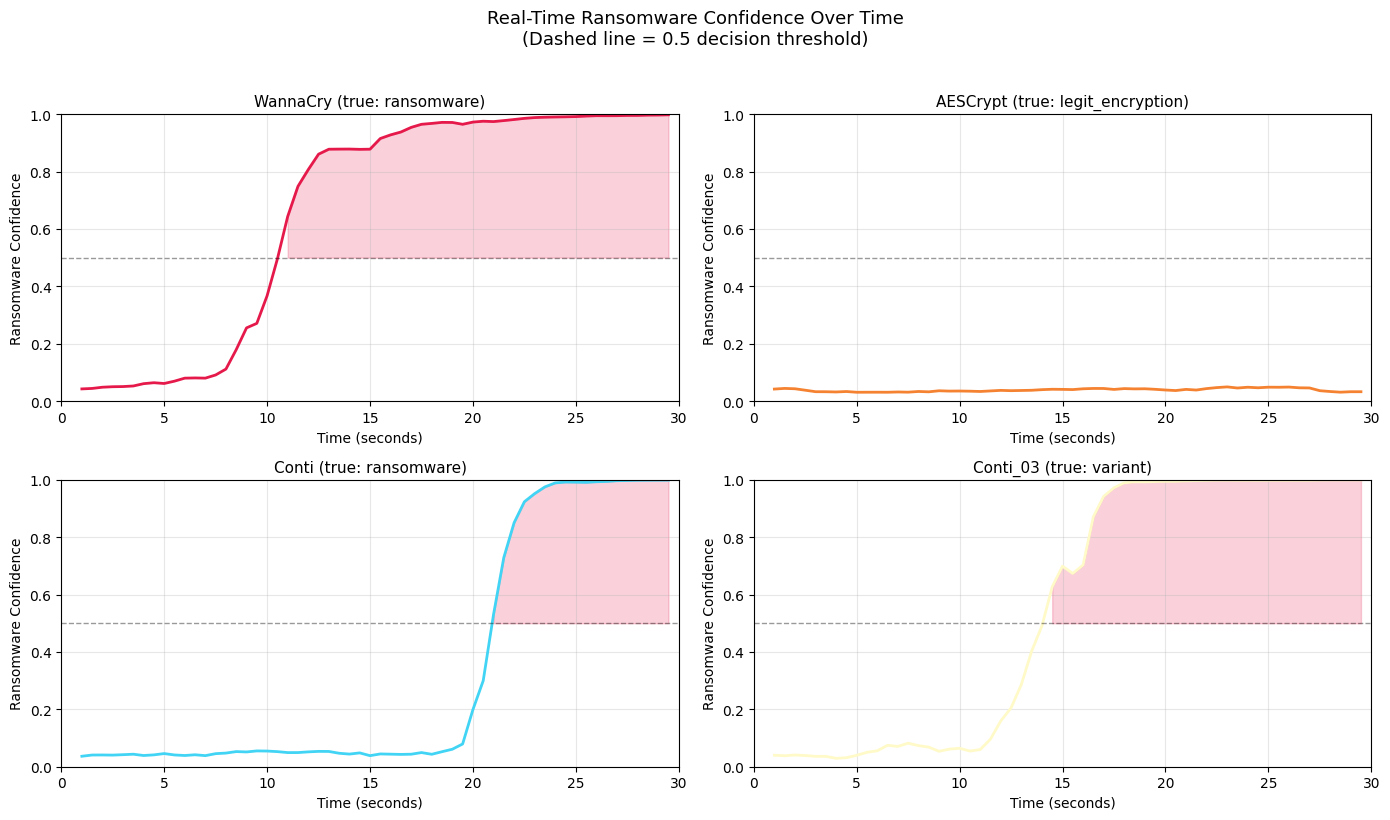

In [15]:
# This cell shows what real-time detection looks like.
# For one WannaCry execution and one AESCrypt execution,
# plot the classifier's ransomware confidence score
# across all 300 time windows.
# This directly shows: can the model distinguish ransomware
# from legitimate encryption as the attack unfolds?

clf_model.eval()

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

show_classes = [
    ("WannaCry",  "ransomware",       "#e6194b"),
    ("AESCrypt",  "legit_encryption", "#f58231"),
    ("Conti",     "ransomware",       "#42d4f4"),
    ("Conti_03",  "variant",          "#fffac8"),
]

ransomware_class_idx = list(le.classes_).index("ransomware")

for ax, (class_name, true_label, color) in zip(axes.flat, show_classes):
    # Find first execution of this class
    mask = all_labels == class_name
    if mask.sum() == 0:
        continue
    idx       = np.where(mask)[0][0]
    seq_tensor = torch.tensor(text_seqs[idx:idx+1],
                               dtype=torch.float32).to(device)

    # Get per-window confidence by processing each window independently
    window_probs = []
    with torch.no_grad():
        # Process full sequence
        logits, _, _ = clf_model(seq_tensor)
        # For temporal view: slide a cumulative window
        for w in range(10, 300, 5):
            partial = seq_tensor[:, :w, :]
            # Pad to 300
            pad_size = 300 - w
            padded   = torch.nn.functional.pad(
                partial.permute(0,2,1), (0, pad_size)
            ).permute(0,2,1)
            logits_w, _, _ = clf_model(padded)
            prob_w = torch.softmax(logits_w, dim=1)[0, ransomware_class_idx].item()
            window_probs.append(prob_w)

    time_axis = [w * T_WINDOW for w in range(10, 300, 5)]
    ax.plot(time_axis, window_probs, color=color, linewidth=2)
    ax.axhline(y=0.5, color="black", linestyle="--", alpha=0.4, linewidth=1)
    ax.fill_between(time_axis, window_probs, 0.5,
                    where=[p > 0.5 for p in window_probs],
                    alpha=0.2, color="#e6194b", label="Above threshold")
    ax.set_title(f"{class_name} (true: {true_label})", fontsize=11)
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Ransomware Confidence")
    ax.set_ylim(0, 1)
    ax.set_xlim(0, 30)
    ax.grid(True, alpha=0.3)

plt.suptitle("Real-Time Ransomware Confidence Over Time\n(Dashed line = 0.5 decision threshold)",
             fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(FEATURES_DIR / "realtime_confidence.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
# Investigate why Conti_06 is classified as benign
# Compare its text windows to known Conti and benign classes

conti06_idx  = np.where(all_labels == "Conti_06")[0][0]
conti_idx    = np.where(all_labels == "Conti")[0][0]
idle_idx     = np.where(all_labels == "Idle")[0][0]

# Show sample windows from each
print("Conti_06 window 100:")
print(all_windows[conti06_idx][100])
print()
print("Known Conti window 100:")
print(all_windows[conti_idx][100])
print()
print("Idle window 100:")
print(all_windows[idle_idx][100])

Conti_06 window 100:
no storage write activity . no memory write activity

Known Conti window 100:
no storage write activity . no memory write activity

Idle window 100:
no storage write activity . memory-write mmio near-zero-entropy . memory-write mmio near-zero-entropy . memory-write mmio near-zero-entropy . memory-write mmio near-zero-entropy . memory-write mmio near-zero-entropy . memory-write mmio near-zero-entropy . memory-write mmio near-zero-entropy . memory-write mmio near-zero-entropy . memory-write mmio near-zero-entropy . memory-write mmio near-zero-entropy . memory-write mmio near-zero-entropy . memory-write mmio near-zero-entropy . memory-write mmio near-zero-entropy . memory-write mmio near-zero-entropy . memory-write mmio near-zero-entropy . memory-write mmio near-zero-entropy . memory-write mmio near-zero-entropy . memory-write mmio near-zero-entropy . memory-write mmio near-zero-entropy . memory-write mmio near-zero-entropy . memory-write mmio near-zero-entropy . memo